In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from brokenbar import config, dsp, features, io, plotting

plotting.apply_style()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)

from scipy import stats
from sklearn.metrics import roc_auc_score

segment 15 s -> resolution 0.067 Hz
supply frequency 59.983 Hz
estimated slip 4.08 %  ->  speed 1726 rpm
sidebands: 55.10 Hz at -29.3 dB, 64.87 Hz at -30.8 dB


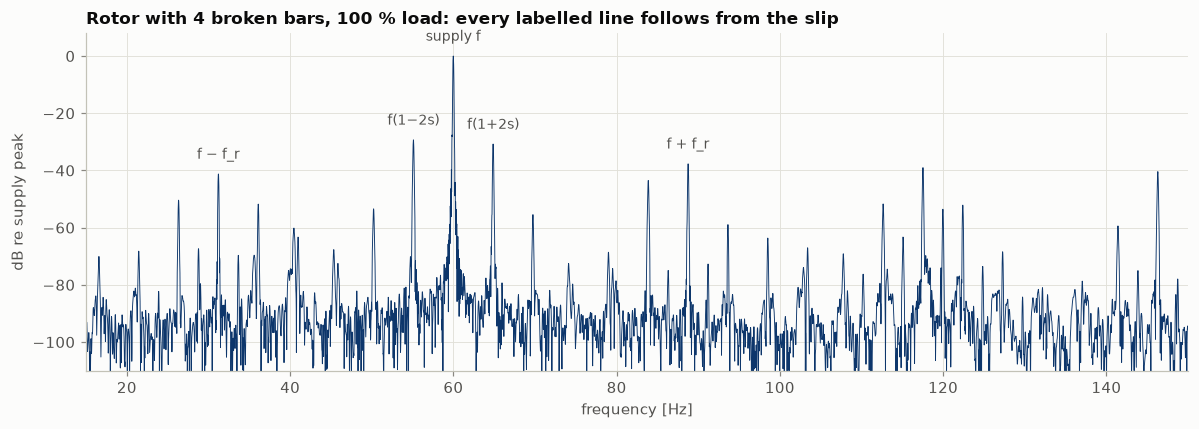

In [2]:
run = io.load_run("r4b", "torque40", 0, ["Ia"])
# 15 s of steady-state current -> Hann FFT
seg = dsp.steady_segment(run["Ia"], config.FS_ELEC, dsp.current_onset(run["Ia"]))
freqs, amp = dsp.amplitude_spectrum(seg, config.FS_ELEC, fmax=150)
# measured supply frequency, spectrum in dB below its peak
f_supply = dsp.supply_frequency(freqs, amp)
db = dsp.db_re_fundamental(freqs, amp, f_supply)
# slip from the eccentricity lines f ± f_r, then the sidebands at f(1 ± 2s)
s = dsp.estimate_slip(freqs, db, f_supply)
sb = dsp.sideband_levels(freqs, db, s, f_supply)
ecc_lo, ecc_hi = dsp.eccentricity_freqs(s, f_supply)
print(f"segment {len(seg) / config.FS_ELEC:.0f} s -> resolution {config.FS_ELEC / len(seg):.3f} Hz")
print(f"supply frequency {f_supply:.3f} Hz")
print(f"estimated slip {100 * s:.2f} %  ->  speed {config.SYNC_SPEED_RPM * (1 - s):.0f} rpm")
print(f"sidebands: {sb['lsb_hz']:.2f} Hz at {sb['lsb_db']:.1f} dB, {sb['usb_hz']:.2f} Hz at {sb['usb_db']:.1f} dB")

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(freqs, db, lw=0.6, color=plotting.BARS_COLORS[4])
marks = {"supply f": f_supply, "f(1−2s)": sb["lsb_hz"], "f(1+2s)": sb["usb_hz"],
         "f − f_r": ecc_lo, "f + f_r": ecc_hi}
for label, fx in marks.items():
    ax.annotate(label, (fx, np.interp(fx, freqs, db)), xytext=(0, 10),
                textcoords="offset points", ha="center", fontsize=9, color=plotting.INK_2)
ax.set(xlim=(15, 150), ylim=(-110, 8), xlabel="frequency [Hz]", ylabel="dB re supply peak",
       title="Rotor with 4 broken bars, 100 % load: every labelled line follows from the slip")
fig.tight_layout()

In [3]:
%%time
# features for every run, computed in parallel and cached in results/
runs, windows, spectra = features.build_feature_tables()
print(runs.shape, windows.shape, spectra["db"].shape)
runs[["run_id", "n_bars", "load_pct", "f_supply", "slip", "slip_vib", "lsb_db", "usb_db", "rms"]].head()

(398, 70) (1194, 15) (398, 9001)
CPU times: user 29.2 ms, sys: 4.15 ms, total: 33.4 ms
Wall time: 36.4 ms


,run_id,n_bars,load_pct,f_supply,slip,slip_vib,lsb_db,usb_db,rms
0,rs_torque05_rep00,0,12.5,60.000,0.004,0.004,-54.916,-54.741,1.070
1,rs_torque05_rep01,0,12.5,60.017,0.004,0.004,-54.373,-54.872,1.069
2,rs_torque05_rep02,0,12.5,60.000,0.004,0.004,-56.973,-52.557,1.066
3,rs_torque05_rep03,0,12.5,60.017,0.004,0.004,-54.092,-53.225,1.067
4,rs_torque05_rep04,0,12.5,59.983,0.004,0.004,-56.159,-53.188,1.065


In [4]:
runs.pivot_table(index="rotor", columns="load_pct", values="f_supply", aggfunc="mean").loc[
    list(config.ROTORS)].round(3)

load_pct,12.5,25.0,37.5,50.0,62.5,75.0,87.5,100.0
rotor,,,,,,,,
rs,60.004,60.002,60.003,59.995,59.995,60.000,60.005,60.010
r1b,60.000,59.993,59.995,59.987,59.985,59.987,59.992,59.998
r2b,59.905,59.952,60.003,60.015,60.000,60.003,60.005,59.993
r3b,60.013,60.000,59.997,59.997,60.003,59.998,59.993,59.995
r4b,60.012,59.953,60.022,60.005,60.002,59.980,59.975,59.976


current vs vibration slip: mean |diff| = 0.026 percentage points, max = 0.039, r = 0.9997


,slip_%,slip_std_%,sideband_offset_hz,bins_from_60Hz
load_pct,,,,
12.5,0.415,0.026,0.498,7.470
25.0,0.885,0.029,1.062,15.925
37.5,1.312,0.052,1.575,23.618
50.0,1.797,0.039,2.157,32.350
62.5,2.266,0.071,2.719,40.791
75.0,2.763,0.076,3.316,49.735
87.5,3.365,0.099,4.038,60.565
100.0,3.947,0.102,4.736,71.038


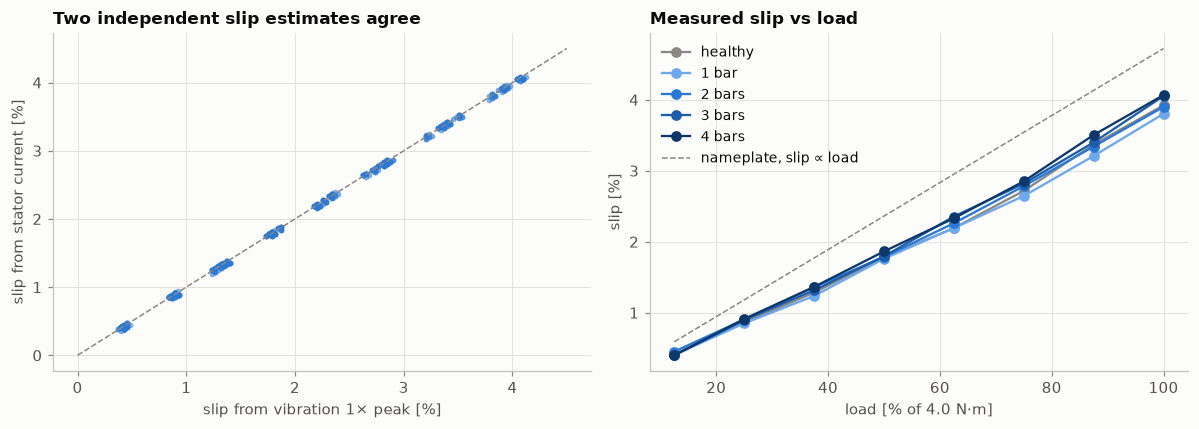

In [5]:
# current-based slip vs vibration-based slip
err = 100 * (runs.slip - runs.slip_vib)
print(f"current vs vibration slip: mean |diff| = {err.abs().mean():.3f} percentage points, "
      f"max = {err.abs().max():.3f}, r = {np.corrcoef(runs.slip, runs.slip_vib)[0, 1]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
ax.scatter(100 * runs.slip_vib, 100 * runs.slip, s=14, color=plotting.BARS_COLORS[2], alpha=0.6, lw=0)
ax.plot([0, 4.5], [0, 4.5], color=plotting.MUTED, lw=1, ls="--")
ax.set(xlabel="slip from vibration 1× peak [%]", ylabel="slip from stator current [%]",
       title="Two independent slip estimates agree")

ax = axes[1]
mean_slip = runs.groupby(["load_pct", "n_bars"]).slip.mean().unstack() * 100
for nb in mean_slip:
    ax.plot(mean_slip.index, mean_slip[nb], marker="o", lw=1.5,
            color=plotting.BARS_COLORS[nb], label=plotting.BARS_LABELS[nb])
ax.plot(plotting.LOAD_TICKS, [config.RATED_SLIP * l for l in plotting.LOAD_TICKS],
        color=plotting.MUTED, ls="--", lw=1, label="nameplate, slip ∝ load")
ax.set(xlabel="load [% of 4.0 N·m]", ylabel="slip [%]", title="Measured slip vs load")
ax.legend()
fig.tight_layout()

slip_by_load = runs.groupby("load_pct").slip.agg(["mean", "std"])
slip_by_load["sideband_offset_hz"] = 2 * slip_by_load["mean"] * config.LINE_FREQ
slip_by_load["bins_from_60Hz"] = slip_by_load.sideband_offset_hz * config.SEGMENT_S
slip_by_load.assign(mean=100 * slip_by_load["mean"], std=100 * slip_by_load["std"]).rename(
    columns={"mean": "slip_%", "std": "slip_std_%"})

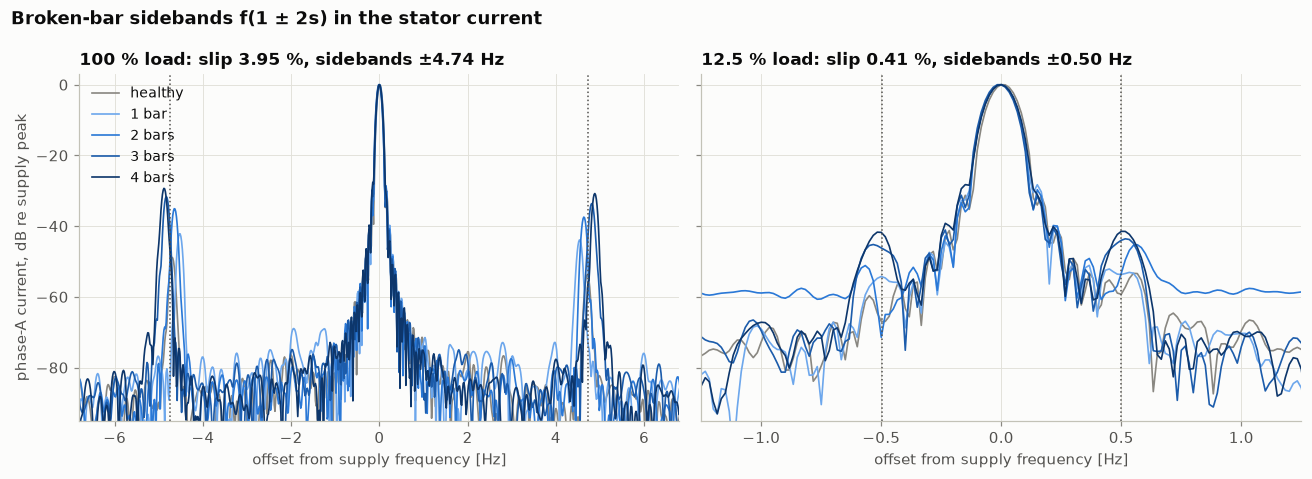

In [6]:
index = {rid: i for i, rid in enumerate(spectra["run_id"])}
by_id = runs.set_index("run_id")
sfreq = spectra["freqs"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for ax, torque, half_span in [(axes[0], "torque40", 6.8), (axes[1], "torque05", 1.25)]:
    slip = runs[runs.torque == torque].slip.mean()
    for rotor, nb in config.ROTORS.items():
        rid = f"{rotor}_{torque}_rep00"
        # x axis relative to each run's own supply frequency
        ax.plot(sfreq - by_id.f_supply[rid], spectra["db"][index[rid]], lw=1.1,
                color=plotting.BARS_COLORS[nb], label=plotting.BARS_LABELS[nb])
    for sign in (-1, 1):
        ax.axvline(2 * sign * slip * config.LINE_FREQ, color=plotting.INK_2, ls=":", lw=1)
    ax.set(xlim=(-half_span, half_span), ylim=(-95, 3), xlabel="offset from supply frequency [Hz]",
           title=f"{config.load_pct(torque):g} % load: slip {100 * slip:.2f} %, "
                 f"sidebands ±{2 * slip * 60:.2f} Hz")
axes[0].set_ylabel("phase-A current, dB re supply peak")
axes[0].legend(loc="upper left")
fig.suptitle("Broken-bar sidebands f(1 ± 2s) in the stator current", x=0.01, ha="left",
             fontweight="bold")
fig.tight_layout()

load_pct,12.5,25.0,37.5,50.0,62.5,75.0,87.5,100.0
n_bars,,,,,,,,
0,-55.5,-59.0,-58.3,-56.6,-55.3,-54.0,-52.2,-51.1
1,-53.5,-51.0,-48.9,-47.1,-45.8,-44.6,-43.1,-41.8
2,-48.5,-44.6,-42.2,-40.5,-39.1,-37.8,-36.5,-35.1
3,-44.7,-40.7,-38.7,-37.2,-35.9,-34.9,-33.5,-32.0
4,-43.0,-39.2,-37.0,-35.5,-34.2,-32.6,-30.8,-29.4


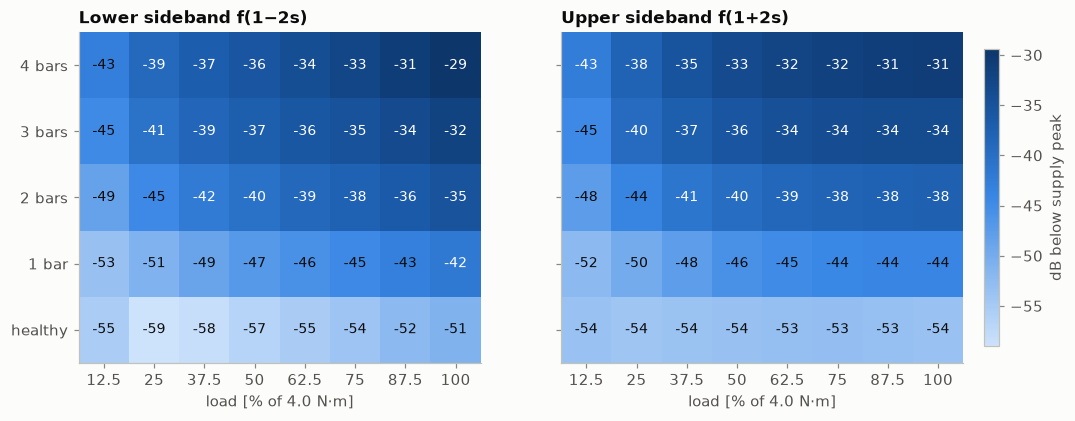

In [7]:
tabs = {col: runs.pivot_table(index="n_bars", columns="load_pct", values=col, aggfunc="mean")
        for col in ("lsb_db", "usb_db")}
vmin = min(t.values.min() for t in tabs.values())
vmax = max(t.values.max() for t in tabs.values())

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9), sharey=True)
titles = {"lsb_db": "Lower sideband f(1−2s)", "usb_db": "Upper sideband f(1+2s)"}
for ax, (col, tab) in zip(axes, tabs.items()):
    im = ax.imshow(tab.values, cmap=plotting.SEQUENTIAL, vmin=vmin, vmax=vmax,
                   aspect="auto", origin="lower")
    for i in range(tab.shape[0]):
        for j in range(tab.shape[1]):
            v = tab.values[i, j]
            dark_cell = (v - vmin) / (vmax - vmin) > 0.55
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=9,
                    color="white" if dark_cell else plotting.INK)
    ax.set_xticks(range(tab.shape[1]), [f"{l:g}" for l in tab.columns])
    ax.set_yticks(range(tab.shape[0]), [plotting.BARS_LABELS[n] for n in tab.index])
    ax.grid(False)
    ax.set(xlabel="load [% of 4.0 N·m]", title=titles[col])
fig.colorbar(im, ax=axes, label="dB below supply peak", shrink=0.9, pad=0.02)
tabs["lsb_db"].round(1)

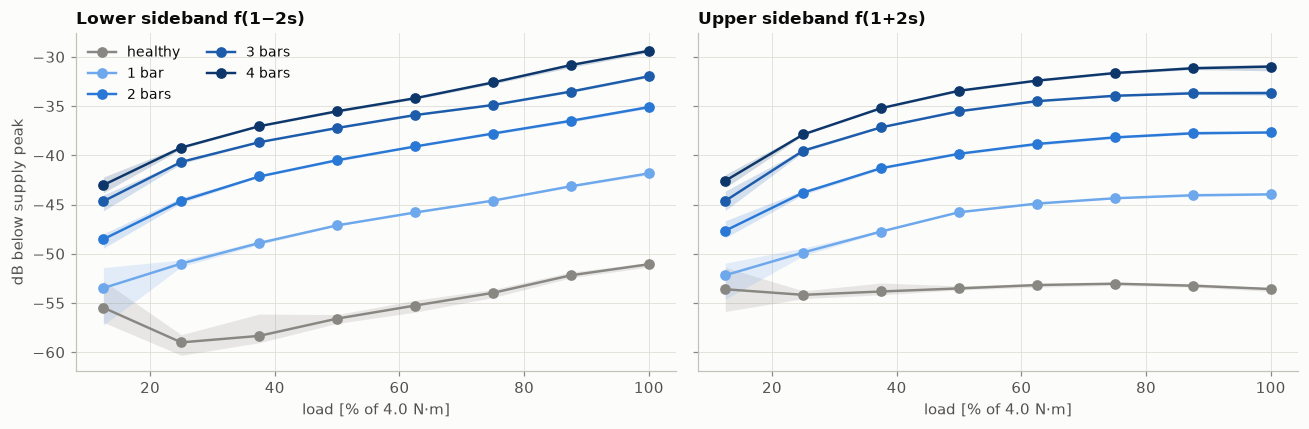

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, col in zip(axes, ("lsb_db", "usb_db")):
    g = runs.groupby(["n_bars", "load_pct"])[col].agg(["mean", "min", "max"])
    for nb in config.ROTORS.values():
        d = g.loc[nb]
        ax.fill_between(d.index, d["min"], d["max"], color=plotting.BARS_COLORS[nb], alpha=0.18, lw=0)
        ax.plot(d.index, d["mean"], marker="o", lw=1.6, color=plotting.BARS_COLORS[nb],
                label=plotting.BARS_LABELS[nb])
    ax.set(xlabel="load [% of 4.0 N·m]", title=titles[col])
axes[0].set_ylabel("dB below supply peak")
axes[0].legend(loc="upper left", ncols=2)
fig.tight_layout()

In [9]:
# threshold-only detector: AUC of the sideband level at each load
rows = []
for load, d in runs.groupby("load_pct"):
    one = d[d.n_bars <= 1]
    rows.append({
        "load_pct": load,
        "auc_lsb": roc_auc_score(d.faulty, d.lsb_db),
        "auc_usb": roc_auc_score(d.faulty, d.usb_db),
        "auc_lsb_1bar": roc_auc_score(one.faulty, one.lsb_db),
        # weakest 1-bar run minus strongest healthy run
        "margin_1bar_db": d[d.n_bars == 1].lsb_db.min() - d[d.n_bars == 0].lsb_db.max(),
        "spearman_bars": stats.spearmanr(d.n_bars, d.lsb_db).statistic,
    })
separability = pd.DataFrame(rows).set_index("load_pct")
separability.to_csv(config.RESULTS_DIR / "physics_separability.csv")
separability.round(3)

,auc_lsb,auc_usb,auc_lsb_1bar,margin_1bar_db,spearman_bars
load_pct,,,,,
12.5,0.95,0.95,0.8,-4.494,0.962
25.0,1.00,1.00,1.0,6.889,0.980
37.5,1.00,1.00,1.0,7.049,0.980
50.0,1.00,1.00,1.0,9.006,0.980
62.5,1.00,1.00,1.0,8.839,0.980
75.0,1.00,1.00,1.0,8.956,0.980
87.5,1.00,1.00,1.0,8.629,0.980
100.0,1.00,1.00,1.0,8.892,0.980


minimum T = 4 / (2 s f) per load [s]:
load_pct
12.5     8.0
25.0     3.8
37.5     2.5
50.0     1.9
62.5     1.5
75.0     1.2
87.5     1.0
100.0    0.8

median |slip error| vs vibration reference [percentage points]:


,12.5,25.0,37.5,50.0,62.5,75.0,87.5,100.0
1,0.377,0.067,0.399,0.121,0.239,0.287,0.070,0.214
2,0.017,0.066,0.066,0.121,0.156,0.122,0.069,0.121
4,0.017,0.037,0.059,0.087,0.052,0.059,0.064,0.058
8,0.035,0.037,0.026,0.018,0.027,0.022,0.025,0.032
15,0.017,0.017,0.017,0.017,0.017,0.018,0.018,0.037


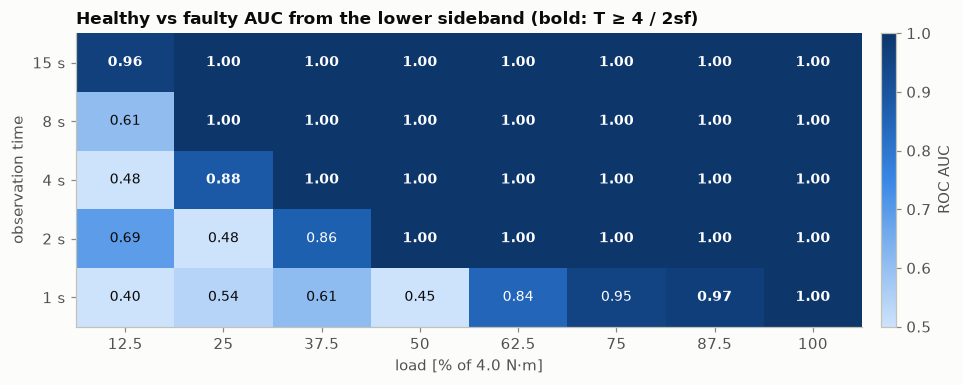

In [10]:
# AUC when slip and sidebands come from only the first T seconds
lengths = features.WINDOW_LENGTHS_S
auc_T = pd.DataFrame(
    {T: [roc_auc_score(d.faulty, d[f"lsb_db_T{T}"]) for _, d in runs.groupby("load_pct")]
     for T in lengths},
    index=sorted(runs.load_pct.unique())).T
slip_err_T = pd.DataFrame(
    {T: [100 * (d[f"slip_T{T}"] - d.slip_vib).abs().median() for _, d in runs.groupby("load_pct")]
     for T in lengths},
    index=sorted(runs.load_pct.unique())).T
# textbook minimum: 4 FFT bins between sideband and supply peak
t_min = 4 / (2 * slip_by_load["mean"] * config.LINE_FREQ)

fig, ax = plt.subplots(figsize=(9.5, 3.6))
im = ax.imshow(auc_T.values, cmap=plotting.SEQUENTIAL, vmin=0.5, vmax=1, aspect="auto", origin="lower")
for i, T in enumerate(lengths):
    for j, load in enumerate(auc_T.columns):
        v = auc_T.values[i, j]
        enough = T >= t_min.loc[load]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9,
                color="white" if v > 0.8 else plotting.INK,
                fontweight="bold" if enough else "normal")
ax.set_xticks(range(len(auc_T.columns)), [f"{l:g}" for l in auc_T.columns])
ax.set_yticks(range(len(lengths)), [f"{T} s" for T in lengths])
ax.grid(False)
ax.set(xlabel="load [% of 4.0 N·m]", ylabel="observation time",
       title="Healthy vs faulty AUC from the lower sideband (bold: T ≥ 4 / 2sf)")
fig.colorbar(im, ax=ax, label="ROC AUC", pad=0.02)
fig.tight_layout()

print("minimum T = 4 / (2 s f) per load [s]:")
print(t_min.round(1).to_string())
print("\nmedian |slip error| vs vibration reference [percentage points]:")
slip_err_T.round(3)